In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from data_cleaning import (AFRICAN_COUNTRY_CODES, categorize_production, country_coverage,
                           is_country_code, prepare_powerbi_dataset, reference_year)

In [2]:
df = pd.read_csv('electricity_generation.csv')
df.head()

,Entity,Code,Year,Electricity generation - TWh
0,ASEAN (Ember),NaN,2000,378.61
1,ASEAN (Ember),NaN,2001,404.85
2,ASEAN (Ember),NaN,2002,433.19
3,ASEAN (Ember),NaN,2003,458.24
4,ASEAN (Ember),NaN,2004,496.56


## cleaning process of the data

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7981 entries, 0 to 7980
Data columns (total 4 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Entity                        7981 non-null   str    
 1   Code                          6418 non-null   str    
 2   Year                          7981 non-null   int64  
 3   Electricity generation - TWh  7981 non-null   float64
dtypes: float64(1), int64(1), str(2)
memory usage: 249.5 KB


In [4]:
df.isnull().sum()

Entity                             0
Code                            1563
Year                               0
Electricity generation - TWh       0
dtype: int64

La colonne `Code` contient le code ISO 3166-1 alpha-3 de chaque pays. Les valeurs manquantes correspondent aux **agrégats** (continents, régions des différentes sources, groupes de revenus, G20, OCDE...) et `World` porte le code `OWID_WRL`.  
Plutôt que d'écrire à la main la liste des régions à supprimer (la première version de cette liste oubliait 27 agrégats comme `G20 (Ember)`, `OECD (EI)`, `European Union (27)` ou `High-income countries`, qui se retrouvaient ensuite classés parmi les pays à forte production), on utilise cette colonne pour ne garder que les pays (`data_cleaning.is_country_code`). Le Kosovo, qui n'a pas de code ISO officiel, est conservé grâce à son code `OWID_KOS`.

In [5]:
# showing of  the entities  that are in the datasets in order to clean the continents as the analysis will mainly focus the countries
df['Entity'].unique()

<StringArray>
[      'ASEAN (Ember)',         'Afghanistan',              'Africa',
         'Africa (EI)',      'Africa (Ember)',             'Albania',
             'Algeria',      'American Samoa',              'Angola',
 'Antigua and Barbuda',
 ...
          'Uzbekistan',             'Vanuatu',           'Venezuela',
             'Vietnam', 'Western Africa (EI)',      'Western Sahara',
               'World',               'Yemen',              'Zambia',
            'Zimbabwe']
Length: 260, dtype: str

In [6]:
# entités qui ne sont pas des pays (agrégats) : elles seront supprimées
aggregates = df.loc[~is_country_code(df['Code']), 'Entity'].unique()
print(len(aggregates), 'agrégats')
aggregates

45 agrégats


<StringArray>
[                      'ASEAN (Ember)',                              'Africa',
                         'Africa (EI)',                      'Africa (Ember)',
                                'Asia',                        'Asia (Ember)',
                   'Asia Pacific (EI)',                            'CIS (EI)',
                'Central America (EI)',                          'EU (Ember)',
                 'Eastern Africa (EI)',                              'Europe',
                         'Europe (EI)',                      'Europe (Ember)',
                 'European Union (27)',                         'G20 (Ember)',
                          'G7 (Ember)',               'High-income countries',
 'Latin America and Caribbean (Ember)',                'Low-income countries',
       'Lower-middle-income countries',                  'Middle Africa (EI)',
                    'Middle East (EI)',                 'Middle East (Ember)',
                       'Non-OECD (EI)'

In [7]:
# suppression des agrégats pour ne garder que les pays, suppression de la colonne 'Code'
# et conversion de la colonne 'Year' au format datetime
df_countries = prepare_powerbi_dataset(df)
print(df.shape, df_countries.shape, df_countries['Entity'].nunique(), 'pays')
df_countries.info()

(7981, 4) (6378, 3) 215 pays
<class 'pandas.DataFrame'>
RangeIndex: 6378 entries, 0 to 6377
Data columns (total 3 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   Entity                        6378 non-null   str           
 1   Year                          6378 non-null   datetime64[us]
 2   Electricity generation - TWh  6378 non-null   float64       
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 149.6 KB


In [8]:
# enregistrement du nouveau dataframe dans un fichier excel (source du rapport Power BI)
df_countries.to_excel('electricity_generation_countries.xlsx', index=False)

### Couverture temporelle des données
Toutes les années ne sont pas renseignées pour tous les pays : les séries de l'Energy Institute commencent en 1985 (environ 80 pays), celles d'Ember en 2000, et les années les plus récentes ne sont pas encore publiées pour tous les pays. Une somme ou une comparaison sur ces années mélange donc des ensembles de pays différents.

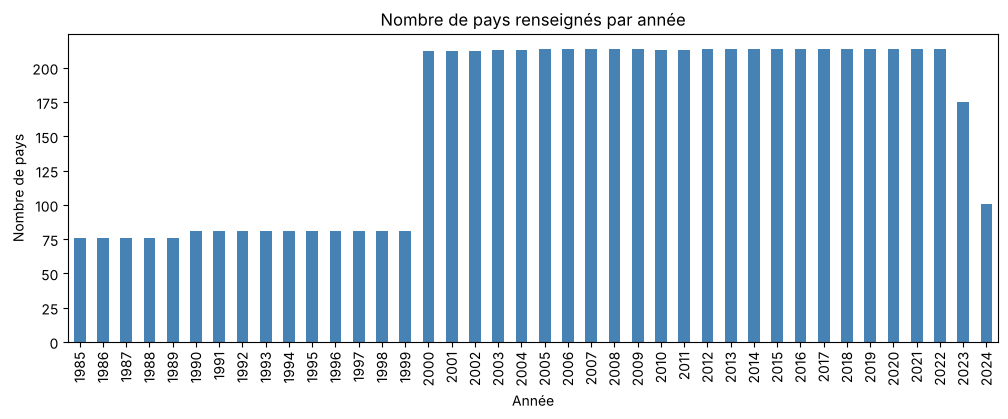

Année de référence : 2022 - 214 pays sur 215


In [9]:
coverage = country_coverage(df_countries)
coverage.plot(kind='bar', color='steelblue', figsize=(12, 4))
plt.title('Nombre de pays renseignés par année')
plt.xlabel('Année')
plt.ylabel('Nombre de pays')
plt.show()

# dernière année renseignée pour (presque) tous les pays : année de référence pour comparer les pays
ref_year = reference_year(df_countries)
print('Année de référence :', ref_year, '-', coverage[ref_year], 'pays sur', df_countries['Entity'].nunique())

In [10]:
df2= df_countries.copy()
df2.rename(columns={'Electricity generation - TWh':'elec_prod' }, inplace=True)
df2.head()

,Entity,Year,elec_prod
0,Afghanistan,2000-01-01,0.48
1,Afghanistan,2001-01-01,0.69
2,Afghanistan,2002-01-01,0.71
3,Afghanistan,2003-01-01,0.91
4,Afghanistan,2004-01-01,0.79


In [11]:
df2.describe()

,Year,elec_prod
count,6378,6378.000000
mean,2008-01-09 06:39:10.329256,116.340187
min,1985-01-01 00:00:00,0.000000
25%,2001-01-01 00:00:00,1.380000
50%,2009-01-01 00:00:00,12.711000
75%,2016-01-01 00:00:00,58.557500
max,2024-01-01 00:00:00,10072.600000
std,NaN,491.142406


## ANALYSE UNIVARIEE

L'analyse univariée va principalement se porter sur la production energetique 

In [12]:
df2['elec_prod'].describe()

count     6378.000000
mean       116.340187
std        491.142406
min          0.000000
25%          1.380000
50%         12.711000
75%         58.557500
max      10072.600000
Name: elec_prod, dtype: float64

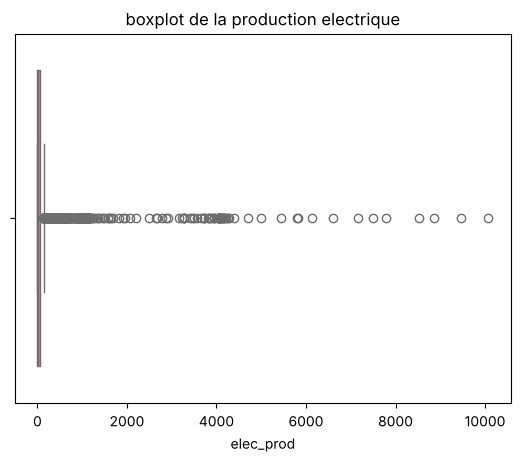

In [13]:
sns.boxplot(x= df2['elec_prod'], color='lightcoral')
plt.title('boxplot de la production electrique')
plt.show()


In [14]:
# écart interquartile, skewness, kurtosis
q1 = df2['elec_prod'].quantile(0.25)
q3 = df2['elec_prod'].quantile(0.75)
iqr = q3 - q1
skew = df2['elec_prod'].skew()
kurt = df2['elec_prod'].kurtosis()
iqr, skew, kurt

(np.float64(57.1775),
 np.float64(10.470921145867216),
 np.float64(139.7223585481369))

## Interprétation qu'on peut tirer de cette analyse

iqr plus élevée ~57 representant la difference entre le 1er quartile et le 3eme quartile  montre une forte dispersion des valeurs autour de la médiane  
ce qui montre ici des ecarts considerables et disproportionnés  entre la production electrique des pays à travers le monde
  
    Hypotheses:  
   . Mix energetique de certains pays qui ont une forte production electrique  
   . faible exploitation des ressources energetiques de certains pays  
   .Absence des ressources energetiques de certains pays   
   

skew ~ 10.5 (kurtosis ~140) tres elevé pour confirmer que la distrubution est asymétrique avec une forte concentration à gauche . ce qui montre que la moyenne est plus grande que la mediane confirmant ainsi les valeurs obtenues dans les infos statistiques obtenues dnas la cellule precedente. il y en aurait une possibilite d'existence de plusieurs outliers . la distribution n'est pas normale.

   Hypotheses:  
    . forte concentration à gauche de la mediane prouve qu'il y a de nombreux pays qui produisent une quantité insuffisante d'electricité.  
    .En clair, les données contiennent des pays ou années où la production électrique est extraordinairement élevée, ce qui crée une très longue queue à droite.

## Interpretation globale
 En clair ces donnees energetiques montrent que seulement quelques pays produisent plus d'electricité   
 La plupart des pays en produient peu  
 Quelques années où les valeurs moyennes s'explosent  

 En conclusion la distribution n'est pas normale et il nécéssite des methodes d'analyse plus robustes


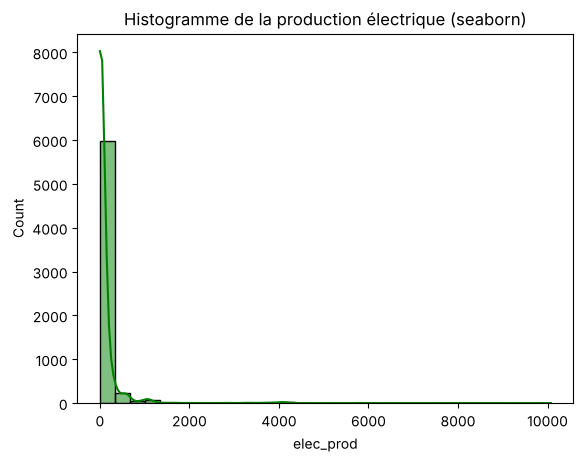

In [15]:

# diminution de bins de frequence pour mieux voir la distribution
sns.histplot(df2['elec_prod'], kde = True, color='green', edgecolor='black', bins=30)
plt.title('Histogramme de la production électrique (seaborn)')

plt.show()

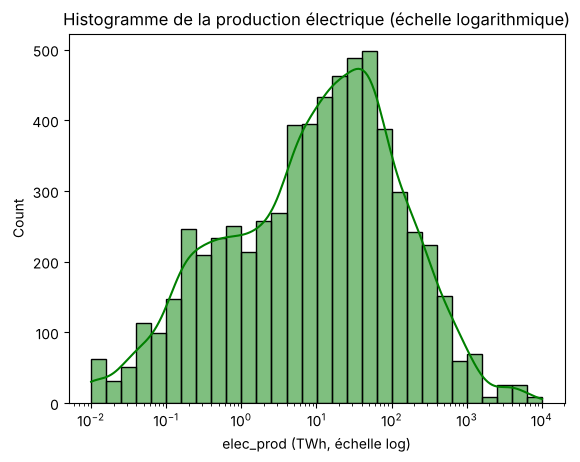

In [16]:
# la distribution étant très asymétrique, une échelle logarithmique la rend lisible
sns.histplot(df2.loc[df2['elec_prod'] > 0, 'elec_prod'], log_scale=True, kde=True, color='green', edgecolor='black', bins=30)
plt.title('Histogramme de la production électrique (échelle logarithmique)')
plt.xlabel('elec_prod (TWh, échelle log)')
plt.show()

Sur une échelle logarithmique, la distribution devient proche d'une cloche : les productions des pays s'étalent sur plusieurs ordres de grandeur (de quelques GWh à plusieurs milliers de TWh). C'est pourquoi les classes de production définies plus bas suivent elles aussi une échelle logarithmique.

## Analyse et interprétation


### Vérification de certaines informations pertinentes

In [17]:
# countries that have electricity production equal to zero
zero_prod_countries = df2[df2['elec_prod'] == 0]['Entity'].unique()
zero_prod_countries

<StringArray>
['Niue']
Length: 1, dtype: str

verification de la raison pour laquelle ce pays a une production electrique nulle durant toute la periode 1985-2024.  
Suite à une recherche menée sur Internet NIUE est l'un des petits pays du monde avec une superficie de 261 km2 . c'est pays insulaire qui se situe dans l'ocean pacifique sud. les donnée obteues ici sur la production electrique de NIUE sont elles fiables ? toutes ces données sont elles représentées ou c'est pour quelques années seulement qui sont recueillies.   pour répondre à cette question la source: https://www.worldometers.info/fr/electricite/niue-electricite/ qui represante la consommation energetique de NIUE en 2016 nous en dira plus . bien avant de la consulter verififons les années sur lesqquelles NIUE a assuré sa production .

In [18]:
df2[df2['Entity']=='Niue']

,Entity,Year,elec_prod
4130,Niue,2000-01-01,0.0
4131,Niue,2001-01-01,0.0
4132,Niue,2002-01-01,0.0
4133,Niue,2003-01-01,0.0
4134,Niue,2004-01-01,0.0
4135,Niue,2005-01-01,0.0
4136,Niue,2006-01-01,0.0
4137,Niue,2007-01-01,0.0
4138,Niue,2008-01-01,0.0
4139,Niue,2009-01-01,0.0


le resultat montre ici clairement que NIUE sur toute la periode s'étalant sur l'intervalle 2001-2022 qu'il n'a eu aucune production electrique , deja avec la valeur nulle obtenue , nous pouvons tous rapidement savoir que ses données sont mal recueillies puisqu'aucun pays à l'heure actuelle ne peut vivre sans l'électricité. mais ce qui m'a poussé encore loin dans la recherche ,peut etre qu'il serait une entité contemporaine qui continue par vivre une histoire ancienne . pour trancher rapidement ça je me suis référé à cette source qui apporte encore de la  lumiere sur sa prodution énergetique en 2016. un petit scraping pour voir ses sources de production energetique

In [19]:
url=  'https://www.worldometers.info/fr/electricite/niue-electricite/'

In [20]:
# Import et utilisation de la fonction scrape_table_from_url
from scraper_utils import scrape_table_from_url, close_browser

# Scraper le tableau depuis l'URL (nécessite Chrome et une connexion Internet)
try:
    df_NIUE = scrape_table_from_url(url, headless=True, timeout_secs=30)
    # Fermer le navigateur pour libérer les ressources
    close_browser()
except Exception as e:
    print('Scraping impossible (Chrome ou connexion Internet indisponible) :', repr(e))
    df_NIUE = pd.DataFrame()

# Afficher un aperçu
if not df_NIUE.empty:
    display(df_NIUE.head())
else:
    print("Aucune donnée n'a été extraite. Valeurs relevées sur la page lors du premier scraping : "
          "consommation électrique 2 790 MWh, production électrique 3 000 MWh (2016).")

Scraping impossible (Chrome ou connexion Internet indisponible) : ModuleNotFoundError("No module named 'helium'")
Aucune donnée n'a été extraite. Valeurs relevées sur la page lors du premier scraping : consommation électrique 2 790 MWh, production électrique 3 000 MWh (2016).


*** Les données présentées dans le tableau concernent l'année 2016, la dernière année pour laquelle les données sont complètes dans toutes les catégories***  
selon la source.

La production de Niue n'est donc pas nulle : elle vaut **3 000 MWh, soit 0,003 TWh**. Or le jeu de données est exprimé en TWh avec deux décimales (précision de 0,01 TWh) : la valeur est simplement **arrondie à 0**. Ce n'est pas une erreur de collecte mais une limite de précision, que l'on retrouve chez d'autres petits territoires dont la production est à peine au-dessus du seuil.

In [21]:
# 1 TWh = 1 000 000 MWh
niue_prod_twh = 3000 / 1e6
print('Production de Niue en 2016 :', niue_prod_twh, 'TWh, arrondie à 2 décimales :', round(niue_prod_twh, 2), 'TWh')

# autres petits territoires en 2016 : valeurs à la limite de la précision du jeu de données
df2[(df2['Year'].dt.year == 2016) & (df2['elec_prod'] <= 0.05)]

Production de Niue en 2016 : 0.003 TWh, arrondie à 2 décimales : 0.0 TWh


,Entity,Year,elec_prod
1271,Cook Islands,2016-01-01,0.03
1881,Falkland Islands,2016-01-01,0.02
3063,Kiribati,2016-01-01,0.03
3787,Montserrat,2016-01-01,0.01
3923,Nauru,2016-01-01,0.03
4146,Niue,2016-01-01,0.00
4794,Saint Helena,2016-01-01,0.01
4863,Saint Pierre and Miquelon,2016-01-01,0.05


La valeur de Niue n'étant pas exploitable (0 au lieu de 0,003 TWh), on la retire de la suite de l'analyse.

In [22]:
# suppression de NUIE dans le dataframe principal
df2_new = df2[df2['Entity'] != 'Niue']
df2_new[df2_new['Entity']=='Niue']  # verification de la suppression

,Entity,Year,elec_prod


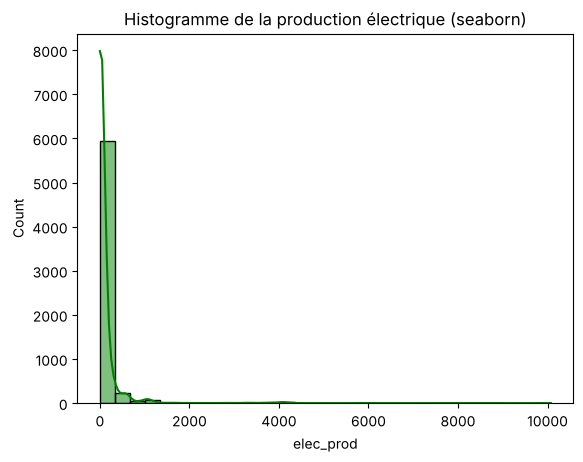

In [23]:

# diminution de bins de frequence pour mieux voir la distribution
sns.histplot(df2_new['elec_prod'], kde = True, color='green', edgecolor='black', bins=30)
plt.title('Histogramme de la production électrique (seaborn)')

plt.show()

### Production annuelle par pays
Additionner la production de toutes les années favoriserait les pays renseignés depuis 1985 (40 ans de données) face à ceux qui ne le sont que depuis 2000 (25 ans) ou moins. Pour comparer les pays sur une base commune, on utilise la production de l'**année de référence** déterminée plus haut (dernière année renseignée pour presque tous les pays).

In [24]:
# production électrique de chaque pays pendant l'année de référence
df_ref = df2_new[df2_new['Year'].dt.year == ref_year]

# copy of the countries without NUIE
df3 = df_ref[['Entity', 'elec_prod']].reset_index(drop=True)
df3.head()

,Entity,elec_prod
0,Afghanistan,0.96
1,Albania,6.97
2,Algeria,91.47
3,American Samoa,0.18
4,Angola,17.31


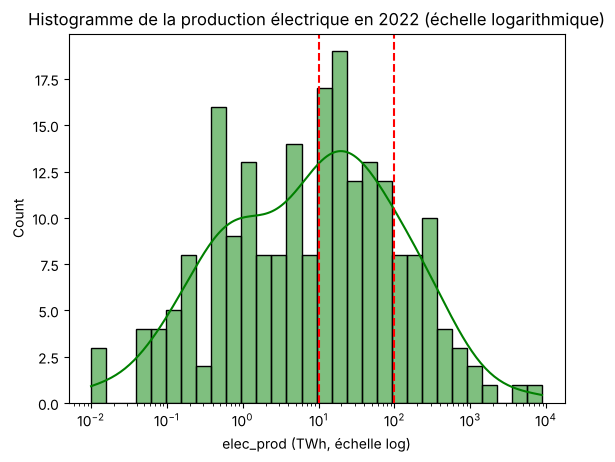

In [25]:
sns.histplot(df3['elec_prod'], log_scale=True, kde=True, color='green', edgecolor='black', bins=30)
# seuils des classes de production (échelle logarithmique)
for threshold in [10, 100]:
    plt.axvline(threshold, color='red', linestyle='--')
plt.title(f'Histogramme de la production électrique en {ref_year} (échelle logarithmique)')
plt.xlabel('elec_prod (TWh, échelle log)')
plt.show()

In [26]:
# Create a new categorical variable from elec production
# (Low < 10 TWh/an <= Medium < 100 TWh/an <= High, voir data_cleaning.categorize_production)
df3['production_category'] = df3['elec_prod'].apply(categorize_production)
df3['production_category'].value_counts()

production_category
Low Production       105
Medium Production     71
High Production       37
Name: count, dtype: int64

In [27]:
# repartir les pays dans le dataframe selon leur categorie de production
df_no_prod = df3[df3['production_category'] == 'No Production']
df_low_prod = df3[df3['production_category'] == 'Low Production']
df_med_prod = df3[df3['production_category'] == 'Medium Production']
df_high_prod = df3[df3['production_category'] == 'High Production']
# creer un nouveau data frame avec les colonnes low production, medium production et high production
df_final = pd.concat([df_low_prod, df_med_prod, df_high_prod], ignore_index=True)
df_final.head()

,Entity,elec_prod,production_category
0,Afghanistan,0.96,Low Production
1,Albania,6.97,Low Production
2,American Samoa,0.18,Low Production
3,Antigua and Barbuda,0.36,Low Production
4,Armenia,9.88,Low Production


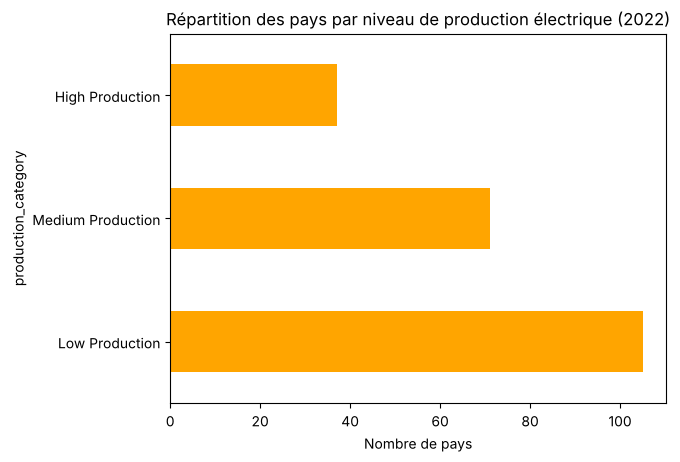

In [28]:
elec_classes = df3['production_category'].value_counts()
elec_classes.plot(kind='barh', color='orange')
plt.title(f'Répartition des pays par niveau de production électrique ({ref_year})')
plt.xlabel('Nombre de pays')
plt.show()

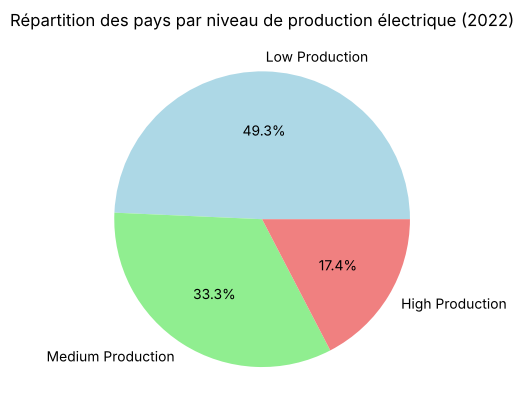

In [29]:
elec_classes.plot(kind='pie', autopct='%1.1f%%', colors=['lightblue', 'lightgreen', 'lightcoral'])
plt.title(f'Répartition des pays par niveau de production électrique ({ref_year})')
plt.ylabel('')
plt.show()

In [30]:

# afficher les pays qui ont une high production
df_high_prod.rename(columns={'Entity': 'High_prod_countries'}).sort_values('elec_prod', ascending=False)

,High_prod_countries,elec_prod,production_category
39,China,8848.71,High Production
203,United States,4286.89,High Production
91,India,1829.30,High Production
159,Russia,1166.94,High Production
99,Japan,1040.57,High Production
25,Brazil,677.17,High Production
33,Canada,658.95,High Production
179,South Korea,624.60,High Production
74,Germany,566.88,High Production
68,France,468.49,High Production


In [31]:
# Middle production countries
df_med_prod.rename(columns={'Entity': 'Med_prod_countries'}).sort_values('elec_prod', ascending=False)

,Med_prod_countries,elec_prod,production_category
17,Belgium,94.33,Medium Production
2,Algeria,91.47,Medium Production
38,Chile,91.04,Medium Production
105,Kuwait,85.29,Medium Production
49,Czechia,83.73,Medium Production
...,...,...,...
87,Honduras,11.77,Medium Production
22,Bolivia,11.67,Medium Production
21,Bhutan,10.77,Medium Production
135,Nepal,10.70,Medium Production


In [32]:
#lower production countries
df_low_prod.rename(columns={'Entity': 'Low_prod_countries'}).sort_values('elec_prod', ascending=False)

,Low_prod_countries,elec_prod,production_category
7,Armenia,9.88,Low Production
190,Tanzania,9.62,Low Production
194,Trinidad and Tobago,9.50,Low Production
61,Estonia,8.94,Low Production
212,Zimbabwe,8.94,Low Production
...,...,...,...
43,Cook Islands,0.04,Low Production
134,Nauru,0.04,Low Production
64,Falkland Islands,0.01,Low Production
129,Montserrat,0.01,Low Production


## Focus Afrique
Les pays africains sont identifiés par leur code ISO (`data_cleaning.AFRICAN_COUNTRY_CODES`, même définition que la région « Africa » d'Our World in Data).

In [33]:
african_countries = df.loc[df['Code'].isin(AFRICAN_COUNTRY_CODES), 'Entity'].unique()
df_africa = df2[df2['Entity'].isin(african_countries)]

# part de l'Afrique dans la production électrique mondiale (somme des pays)
summary = pd.DataFrame({
    'Afrique (TWh)': df_africa.groupby(df_africa['Year'].dt.year)['elec_prod'].sum(),
    'Monde (TWh)': df2.groupby(df2['Year'].dt.year)['elec_prod'].sum(),
}).loc[[2000, ref_year]]
summary["Part de l'Afrique (%)"] = 100 * summary['Afrique (TWh)'] / summary['Monde (TWh)']

growth = 100 * (summary.loc[ref_year] / summary.loc[2000] - 1)
print(f"Croissance 2000-{ref_year} : Afrique {growth['Afrique (TWh)']:.0f} %, Monde {growth['Monde (TWh)']:.0f} %")
summary.round(1)

Croissance 2000-2022 : Afrique 109 %, Monde 89 %


,Afrique (TWh),Monde (TWh),Part de l'Afrique (%)
Year,,,
2000,441.1,15278.7,2.9
2022,923.4,28926.8,3.2


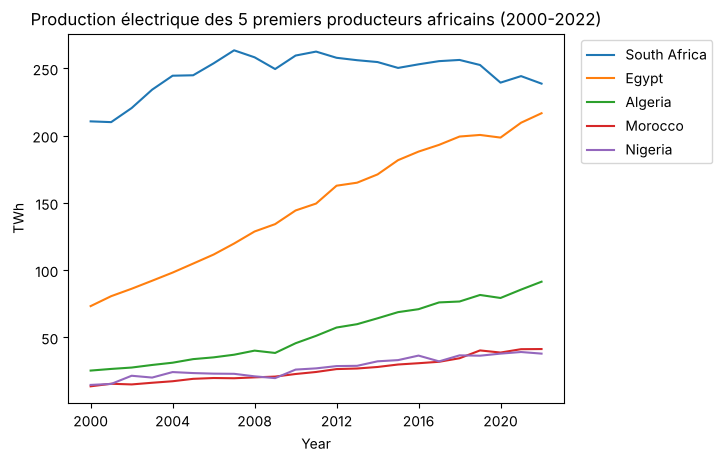

In [34]:
# évolution de la production électrique des 5 premiers producteurs africains (période couverte par tous les pays)
top5_africa = df3[df3['Entity'].isin(african_countries)].nlargest(5, 'elec_prod')['Entity']
df_top5 = df_africa[df_africa['Entity'].isin(top5_africa) & df_africa['Year'].dt.year.between(2000, ref_year)]
sns.lineplot(data=df_top5, x='Year', y='elec_prod', hue='Entity', hue_order=top5_africa)
plt.title(f'Production électrique des 5 premiers producteurs africains (2000-{ref_year})')
plt.ylabel('TWh')
plt.legend(title='', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

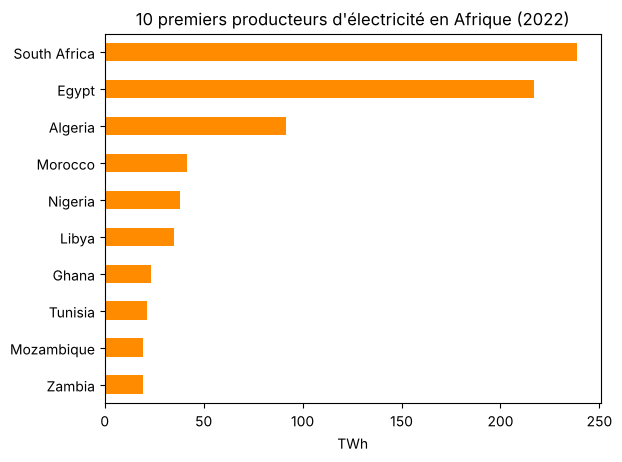

production_category
Low Production       40
Medium Production    14
High Production       2
Name: count, dtype: int64


,Entity,elec_prod,production_category,share_of_africa_%
178,South Africa,238.72,High Production,25.9
57,Egypt,216.71,High Production,23.5
2,Algeria,91.47,Medium Production,9.9
130,Morocco,41.41,Medium Production,4.5
141,Nigeria,38.00,Medium Production,4.1
112,Libya,35.11,Medium Production,3.8
75,Ghana,23.22,Medium Production,2.5
195,Tunisia,21.41,Medium Production,2.3
131,Mozambique,19.56,Medium Production,2.1
211,Zambia,19.47,Medium Production,2.1


In [35]:
df3_africa = df3[df3['Entity'].isin(african_countries)].sort_values('elec_prod', ascending=False)
df3_africa['share_of_africa_%'] = (100 * df3_africa['elec_prod'] / df3_africa['elec_prod'].sum()).round(1)

df3_africa.head(10).plot(kind='barh', x='Entity', y='elec_prod', color='darkorange', legend=False)
plt.gca().invert_yaxis()
plt.title(f'10 premiers producteurs d\'électricité en Afrique ({ref_year})')
plt.xlabel('TWh')
plt.ylabel('')
plt.show()

print(df3_africa['production_category'].value_counts())
df3_africa.head(10)

### Ce que montrent ces chiffres
- En 2022, l'Afrique (56 pays renseignés) ne produit que **3,2 % de l'électricité mondiale** (2,9 % en 2000), alors qu'elle rassemble près de 18 % de la population mondiale (source : ONU).
- Sa production a plus que doublé entre 2000 et 2022 (+109 %), un peu plus vite que la production mondiale (+89 %) : l'écart se réduit, mais très lentement.
- La production est très concentrée : l'Afrique du Sud et l'Égypte en assurent à elles seules près de la moitié (49 %), et les 5 premiers producteurs (avec l'Algérie, le Maroc et le Nigeria) plus des deux tiers (68 %).
- 40 des 56 pays africains sont dans la catégorie *Low Production* (moins de 10 TWh par an) et seuls 2 atteignent la catégorie *High Production*. Le Nigeria, pays le plus peuplé du continent, produit moins d'électricité que le Maroc.
- Les trajectoires divergent : la production de l'Égypte a presque triplé depuis 2000, tandis que celle de l'Afrique du Sud stagne depuis 2007 (hypothèse : crise du système électrique et délestages d'Eskom).

## Analyse des catégories de pays selon leur niveau de production électrique  
### Introduction   

La classification des pays en trois catégories High Production Countries (au moins 100 TWh par an), Medium Production Countries (de 10 à 100 TWh) et Low Production Countries (moins de 10 TWh), établie sur la production de l'année 2022, permet de mieux comprendre la structure mondiale de la production électrique ainsi que les disparités énergétiques. Les sections suivantes présentent les interprétations possibles et les recommandations associées à chaque groupe.  

Pays à haute production électrique  

Les pays de cette catégorie affichent des volumes de production très élevés. On y retrouve 37 pays, dont la Chine, les États-Unis, l’Inde, la Russie, le Japon, le Brésil ou encore le Canada.

Interprétation  

Ces pays possèdent une infrastructure énergétique très développée, capable de soutenir une forte demande industrielle, résidentielle et commerciale. Leur mix énergétique est plus diversifié et combine souvent renouvelables, nucléaire, fossiles et hydroélectricité. Leur influence sur les émissions mondiales est considérable et leurs choix stratégiques peuvent modifier les trajectoires de transition énergétique à l’échelle internationale.

Recommandations 

Encourager une augmentation de la part des énergies renouvelables afin de réduire l’empreinte carbone globale.
Renforcer les investissements dans les réseaux intelligents et les systèmes de stockage.
Améliorer l’efficacité énergétique des industries lourdes qui représentent une part importante de la consommation.
Accélérer le développement des technologies de captage et stockage du carbone pour les secteurs difficiles à décarboner.

Pays à production moyenne

Les pays de cette catégorie présentent une production électrique intermédiaire. Ils possèdent généralement un appareil énergétique en croissance mais pas encore au niveau des grandes puissances.

Interprétation

Ils sont souvent en transition économique. Leur système énergétique peut manquer de diversification et dépendre de quelques sources principales. Leur production augmente généralement avec la croissance démographique et industrielle. Ces pays sont parfois vulnérables aux fluctuations des prix des énergies fossiles.

Recommandations

Diversifier davantage les sources d’énergie pour réduire la dépendance à un unique type de ressource.
Encourager les investissements nationaux et internationaux dans les infrastructures renouvelables.
Renforcer les interconnexions électriques régionales pour sécuriser l’approvisionnement.
Mettre en place des programmes d’efficacité énergétique adaptés aux secteurs résidentiels et manufacturiers.

Pays à faible production électrique

Ces pays affichent les niveaux de production les plus bas. La majorité d’entre eux sont à faible revenu, insulaires ou touchés par une instabilité économique ou politique.

Interprétation

Un faible niveau de production limitent l’accès à une électricité fiable pour la population et l’industrie. Le déficit énergétique ralentit souvent le développement économique. Leur production repose fréquemment sur des solutions coûteuses et polluantes comme le diesel ou des micro installations locales.

Recommandations

Promouvoir des solutions renouvelables décentralisées comme le solaire ou l’éolien pour électrifier les zones isolées.
Mobiliser des financements internationaux pour créer des infrastructures électriques durables.
Former des professionnels locaux pour assurer la maintenance et la pérennité des installations.
Renforcer les cadres institutionnels afin d’attirer de nouveaux investissements dans le secteur énergétique.

Perspectives globales

La forte disparité entre les trois catégories met en évidence une inégalité énergétique mondiale persistante. Les pays à haute production, responsables d’une part majeure des émissions, doivent assumer une responsabilité accrue dans la transition vers un système bas carbone. Les pays à faible production disposent d’un fort potentiel renouvelable mais manquent d’accès au financement et à la technologie.

## Conclusion

Cette classification met en lumière trois dynamiques énergétiques distinctes. Les pays à haute production doivent moderniser et décarboner, les pays à production moyenne doivent diversifier et sécuriser, et les pays à faible production doivent accéder à des infrastructures fiables et durables. Une coopération internationale reste essentielle pour combler les écarts et assurer une transition énergétique équitable.